# 3.1.3 — Function Approximation: Complete Experiments

This notebook uses the existing `MLP` implementation from `shared.mlp` and runs all experiments requested in Section 3.1.3:

1. Function generation and visualisation.
2. Baseline approximation with all data.
3. Hidden-layer size study (1–25, every few).
4. Model comparison and selection of a candidate model.
5. Generalisation with 80%, 60%, 40%, and 20% of the samples.
6. Convergence-speed study through learning rate and momentum.
7. Optional Gaussian-noise experiment.

**Important:** the report should use the *all-data MSE* for the generalisation discussion, as requested by the assignment. The held-out subset is used to inspect generalisation, but the approximation is also evaluated over all 441 available points.

The notebook prints enough numerical information and produces the plots needed to write the report later.


In [141]:
import numpy as np
import sys
import matplotlib.pyplot as plt
sys.path.append('..')
from shared.mlp import MLP

np.set_printoptions(precision=6, suppress=True)
print("Libraries and MLP imported.")

Libraries and MLP imported.


In [142]:
def print_and_save_to_md_output(content):
    print(content)
    with open("output.md", 'a') as f:
        f.write(content + '\n')

def reset_md_output_file():
    with open("output.md", 'w') as f:
        f.write("# Output\n\n")

def plot_surface(xx, yy, values, title, zlim=(-0.7, 0.7), alpha=0.9):
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot_surface(xx, yy, values, alpha=alpha)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("output")
    ax.set_title(title)
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.set_zlim(*zlim)
    plt.show()

def plot_target_vs_output(xx, yy, z, output, title):
    zz = output.reshape(xx.shape)
    fig = plt.figure(figsize=(9, 7))
    ax = fig.add_subplot(111, projection='3d')
    ax.plot_surface(xx, yy, z, alpha=0.45)
    ax.plot_surface(xx, yy, zz, alpha=0.45)
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_zlabel("output")
    ax.set_title(title)
    ax.set_xlim(-5, 5)
    ax.set_ylim(-5, 5)
    ax.set_zlim(-0.7, 0.7)
    plt.show()

def regression_metrics(output, target):
    error = output - target
    return {
        "mse": float(np.mean(error**2)),
        "rmse": float(np.sqrt(np.mean(error**2))),
        "mae": float(np.mean(np.abs(error))),
        "max_abs_error": float(np.max(np.abs(error))),
    }

def convergence_epoch(history, threshold=0.01, key="train_mse"):
    values = history[key]
    hits = np.where(np.asarray(values) < threshold)[0]
    return int(hits[0]) if len(hits) else None

def print_metrics(name, metrics):
    print_and_save_to_md_output(
        f"{name}: "
        f"MSE={metrics['mse']:.8f}, "
        f"RMSE={metrics['rmse']:.8f}, "
        f"MAE={metrics['mae']:.8f}, "
        f"MaxAbsError={metrics['max_abs_error']:.8f}"
    )
    
reset_md_output_file()
    


## 1. Generate the function data

Dataset information
-------------------
x range: -5.0 to 4.5, step=0.5
y range: -5.0 to 4.5, step=0.5
Grid size: 20 x 20
Number of samples: 400
patterns shape: (2, 400)
targets shape: (1, 400)
Target range: [-0.493262, 0.500000]


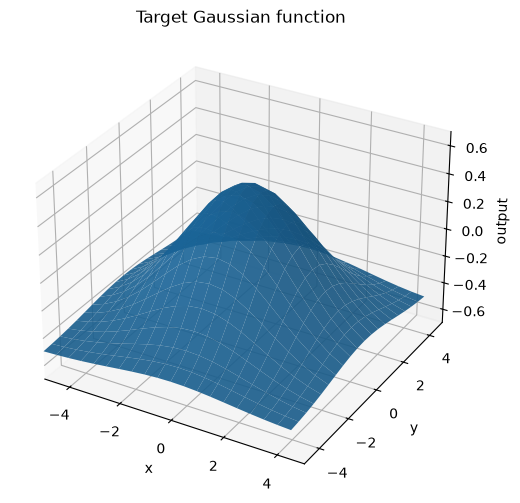

In [143]:
# The assignment specifies x,y in [-5,5] with step 0.5.
x = np.arange(-5, 5, 0.5)
y = np.arange(-5, 5, 0.5)

xx, yy = np.meshgrid(x, y)
z = np.exp(-(xx**2 + yy**2) / 10) - 0.5

patterns = np.vstack((xx.ravel(), yy.ravel()))
targets = z.ravel().reshape(1, -1)

ndata = patterns.shape[1]
gridsize = len(x)

print_and_save_to_md_output("Dataset information")
print_and_save_to_md_output("-------------------")
print_and_save_to_md_output(f"x range: {x[0]} to {x[-1]}, step={x[1]-x[0]}")
print_and_save_to_md_output(f"y range: {y[0]} to {y[-1]}, step={y[1]-y[0]}")
print_and_save_to_md_output(f"Grid size: {gridsize} x {gridsize}")
print_and_save_to_md_output(f"Number of samples: {ndata}")
print_and_save_to_md_output(f"patterns shape: {patterns.shape}")
print_and_save_to_md_output(f"targets shape: {targets.shape}")
print_and_save_to_md_output(f"Target range: [{targets.min():.6f}, {targets.max():.6f}]")

plot_surface(xx, yy, z, "Target Gaussian function")

## 2. Baseline approximation using all 441 samples

A two-layer perceptron is used. The baseline architecture is **2–20–1**, matching the architecture already used in the current notebook.

The numerical output includes final MSE, RMSE, MAE, maximum absolute error, and the first epoch at which MSE falls below 0.01 (if it happens).


BASELINE APPROXIMATION RESULTS:

BASELINE CONFIGURATION
---------------------
Architecture: 2-20-1
eta=0.2, alpha=0.9, epochs=1000, seed=42
Final all-data performance: MSE=0.00010904, RMSE=0.01044238, MAE=0.00850347, MaxAbsError=0.03368805
Initial training MSE: 0.20831094
Final training MSE:   0.00010920
Minimum training MSE: 0.00010920
Epoch of minimum MSE: 999
Epoch with MSE < 0.01: 77


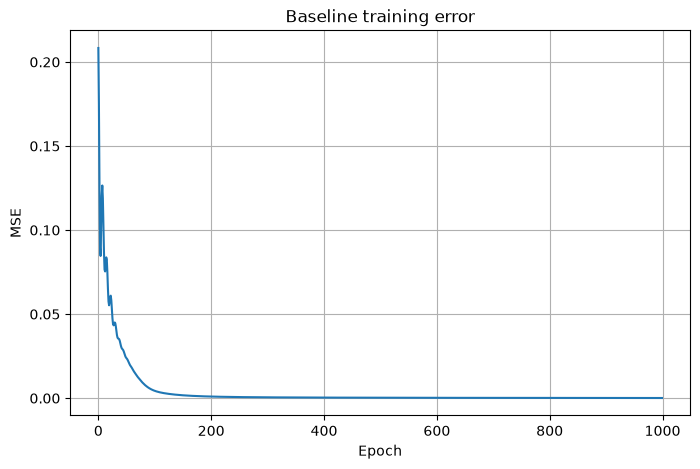

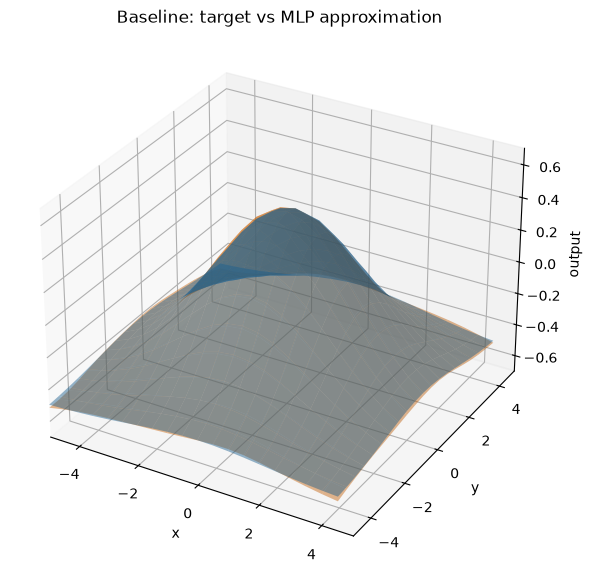

In [144]:
BASE_HIDDEN = 20
BASE_ETA = 0.2
BASE_ALPHA = 0.9
BASE_EPOCHS = 1000
BASE_SEED = 42

baseline = MLP([2, BASE_HIDDEN, 1], seed=BASE_SEED)
baseline_history = baseline.train(
    patterns, targets,
    eta=BASE_ETA,
    alpha=BASE_ALPHA,
    epochs=BASE_EPOCHS,
    mode="batch"
)

baseline_out = baseline.forward(patterns)
baseline_metrics = regression_metrics(baseline_out, targets)

print_and_save_to_md_output("\nBASELINE APPROXIMATION RESULTS:\n")

print_and_save_to_md_output("BASELINE CONFIGURATION")
print_and_save_to_md_output("---------------------")
print_and_save_to_md_output(f"Architecture: 2-{BASE_HIDDEN}-1")
print_and_save_to_md_output(f"eta={BASE_ETA}, alpha={BASE_ALPHA}, epochs={BASE_EPOCHS}, seed={BASE_SEED}")
print_metrics("Final all-data performance", baseline_metrics)
print_and_save_to_md_output(f"Initial training MSE: {baseline_history['train_mse'][0]:.8f}")
print_and_save_to_md_output(f"Final training MSE:   {baseline_history['train_mse'][-1]:.8f}")
print_and_save_to_md_output(f"Minimum training MSE: {np.min(baseline_history['train_mse']):.8f}")
print_and_save_to_md_output(f"Epoch of minimum MSE: {np.argmin(baseline_history['train_mse'])}")
print_and_save_to_md_output(f"Epoch with MSE < 0.01: {convergence_epoch(baseline_history) or 'not reached'}")

fig = plt.figure(figsize=(8, 5))
plt.plot(baseline_history['train_mse'])
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Baseline training error")
plt.grid(True)
plt.show()

plot_target_vs_output(xx, yy, z, baseline_out, "Baseline: target vs MLP approximation")

## 3. Hidden-layer size study: 1 to 25



Hidden Layer Size Studies Results:

  Hidden      Final MSE        Min MSE     Conv.<0.01      MaxAbsErr
----------------------------------------------------------------------
       1     0.06252871     0.06253445              -     0.66695162
       2     0.03791869     0.03791870              -     0.47572288
       3     0.00213734     0.00213765            331     0.14658859
       4     0.00180165     0.00180194            174     0.12673284
       5     0.00030806     0.00030822            192     0.06515217
       7     0.00026887     0.00026904            123     0.07253285
      10     0.00018714     0.00018733            108     0.04825719
      15     0.00028396     0.00028412             91     0.04811397
      20     0.00010904     0.00010920             77     0.03368805
      25     0.00006171     0.00006177             50     0.04578395


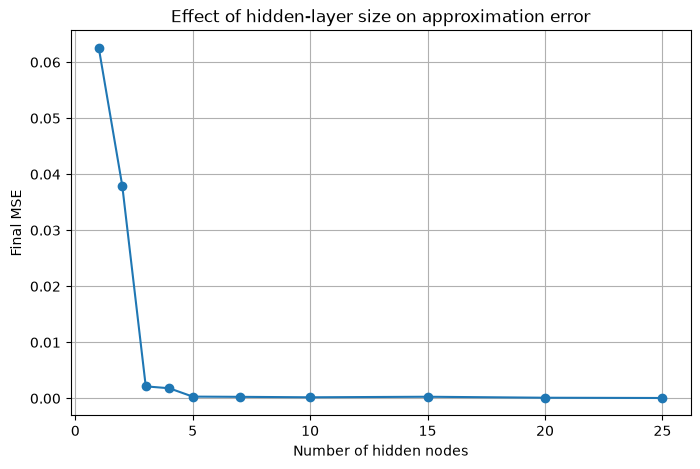

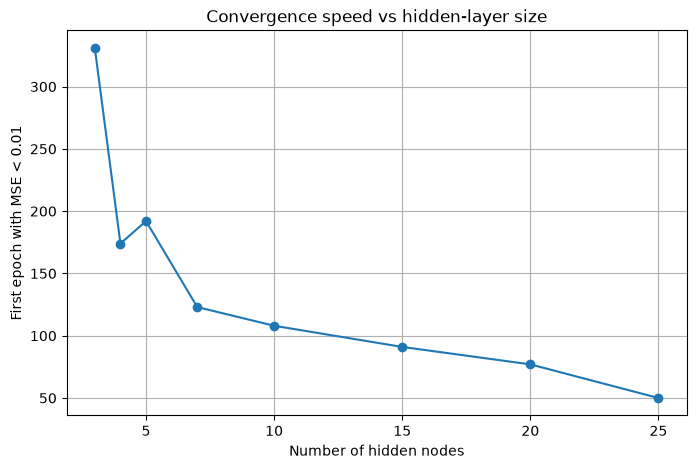

In [145]:
hidden_layer_sizes = [1, 2, 3, 4, 5, 7, 10, 15, 20, 25]
HIDDEN_EPOCHS = 1000

hidden_results = []
print_and_save_to_md_output("\n\nHidden Layer Size Studies Results:\n")
print_and_save_to_md_output(f"{'Hidden':>8} {'Final MSE':>14} {'Min MSE':>14} {'Conv.<0.01':>14} {'MaxAbsErr':>14}")
print_and_save_to_md_output("-" * 70)

for hidden_size in hidden_layer_sizes:
    # Fixed seed makes this architecture comparison easier to reproduce.
    mlp = MLP([2, hidden_size, 1], seed=42)
    history = mlp.train(
        patterns, targets,
        eta=BASE_ETA,
        alpha=BASE_ALPHA,
        epochs=HIDDEN_EPOCHS,
        mode="batch"
    )
    out = mlp.forward(patterns)
    metrics = regression_metrics(out, targets)
    conv = convergence_epoch(history, threshold=0.01)

    row = {
        "hidden": hidden_size,
        "final_mse": metrics["mse"],
        "min_mse": float(np.min(history["train_mse"])),
        "conv_epoch": conv if conv is not None else np.nan,
        "rmse": metrics["rmse"],
        "mae": metrics["mae"],
        "max_abs_error": metrics["max_abs_error"],
        "model": mlp,
        "history": history,
        "output": out,
    }
    hidden_results.append(row)

    print_and_save_to_md_output(
        f"{hidden_size:>8} "
        f"{metrics['mse']:>14.8f} "
        f"{np.min(history['train_mse']):>14.8f} "
        f"{str(conv if conv is not None else '-'):>14} "
        f"{metrics['max_abs_error']:>14.8f}"
    )

# Plot final MSE against hidden-layer size.
plt.figure(figsize=(8, 5))
plt.plot(
    [r["hidden"] for r in hidden_results],
    [r["final_mse"] for r in hidden_results],
    marker="o"
)
plt.xlabel("Number of hidden nodes")
plt.ylabel("Final MSE")
plt.title("Effect of hidden-layer size on approximation error")
plt.grid(True)
plt.show()

# Plot convergence epochs where available.
plt.figure(figsize=(8, 5))
conv_x = [r["hidden"] for r in hidden_results if not np.isnan(r["conv_epoch"])]
conv_y = [r["conv_epoch"] for r in hidden_results if not np.isnan(r["conv_epoch"])]
plt.plot(conv_x, conv_y, marker="o")
plt.xlabel("Number of hidden nodes")
plt.ylabel("First epoch with MSE < 0.01")
plt.title("Convergence speed vs hidden-layer size")
plt.grid(True)
plt.show()
    

### Visual inspection of representative hidden-layer sizes

These plots make the assignment's qualitative questions about **fewer than 5** and **more than 20** hidden nodes easier to discuss.



Representative hidden-layer sizes:
Hidden=1: MSE=0.06252871, RMSE=0.25005742, MAE=0.20257415, MaxAbsError=0.66695162


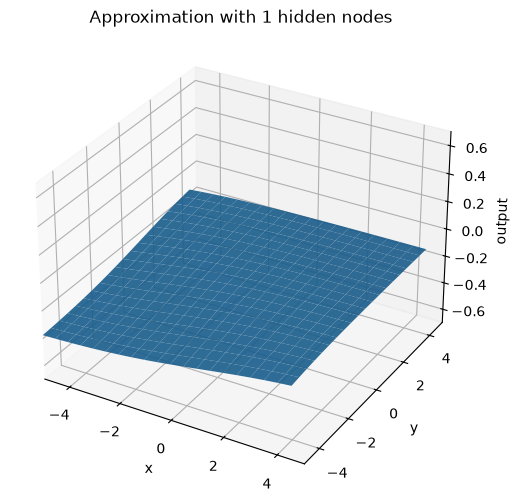

Hidden=3: MSE=0.00213734, RMSE=0.04623132, MAE=0.03410719, MaxAbsError=0.14658859


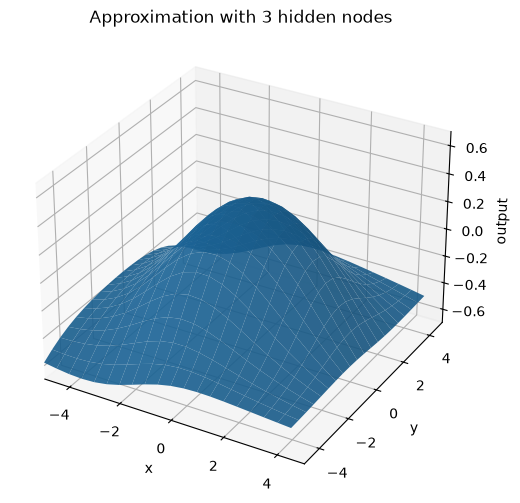

Hidden=5: MSE=0.00030806, RMSE=0.01755174, MAE=0.01300468, MaxAbsError=0.06515217


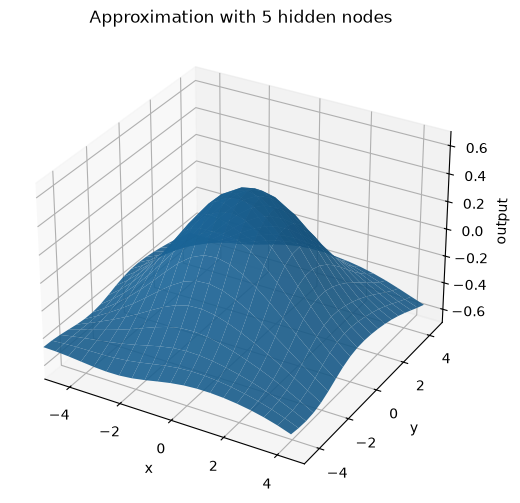

Hidden=10: MSE=0.00018714, RMSE=0.01367979, MAE=0.01096616, MaxAbsError=0.04825719


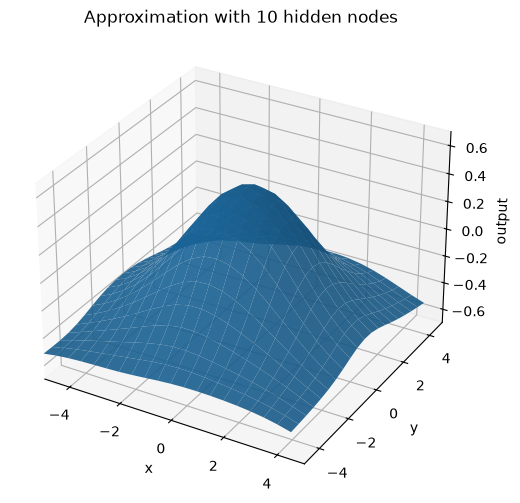

Hidden=20: MSE=0.00010904, RMSE=0.01044238, MAE=0.00850347, MaxAbsError=0.03368805


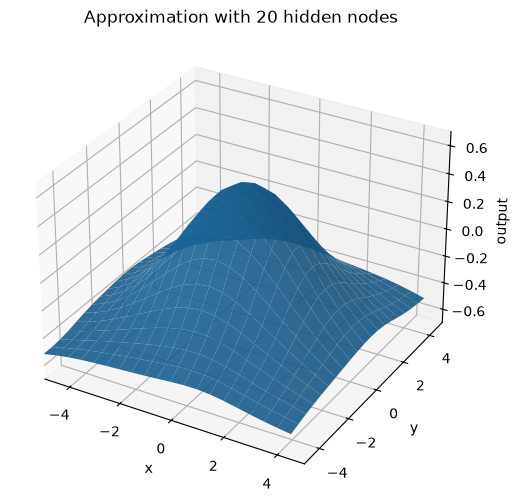

Hidden=25: MSE=0.00006171, RMSE=0.00785577, MAE=0.00583538, MaxAbsError=0.04578395


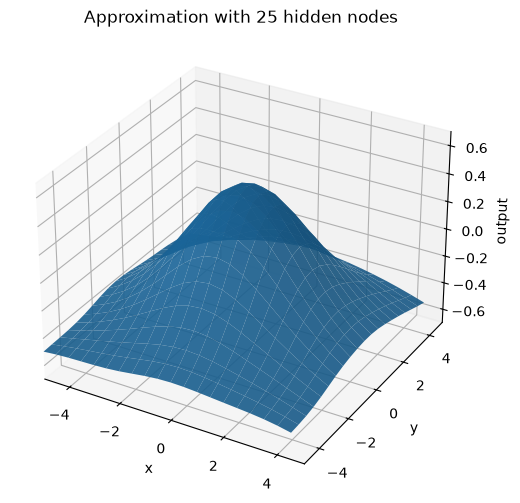

In [146]:
representative_sizes = [1, 3, 5, 10, 20, 25]
print_and_save_to_md_output("\n\nRepresentative hidden-layer sizes:")
for h in representative_sizes:
    row = next(r for r in hidden_results if r["hidden"] == h)
    print_metrics(f"Hidden={h}", regression_metrics(row["output"], targets))
    plot_surface(xx, yy, row["output"].reshape(xx.shape),
                 f"Approximation with {h} hidden nodes")

## 4. Model comparison and candidate selection

For the subsequent experiments we need one candidate architecture. We select the architecture with the lowest final all-data MSE **within this reproducible grid search**.

This is a model-comparison procedure, not a claim that this architecture is universally optimal.



MODEL COMPARISON
----------------
Candidate selected for subsequent experiments: 2-25-1
Final all-data MSE: 0.00006171
RMSE: 0.00785577
MAE: 0.00583538
Maximum absolute error: 0.04578395
Minimum training MSE during run: 0.00006177
Convergence epoch (MSE < 0.01): 50


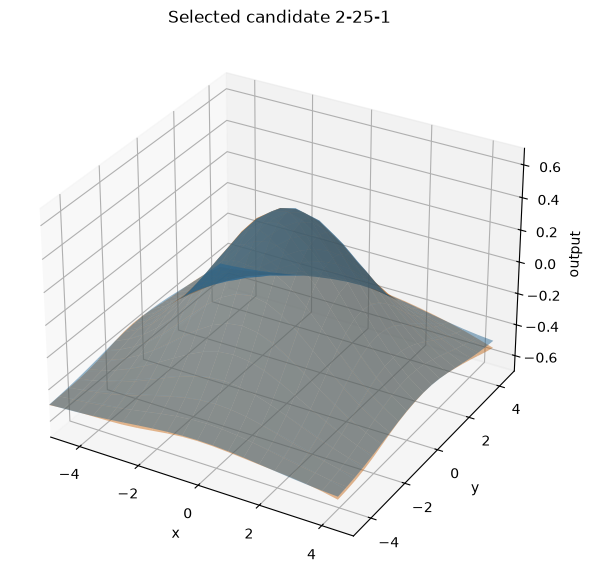

In [147]:
best_hidden_row = min(hidden_results, key=lambda r: r["final_mse"])
BEST_HIDDEN = best_hidden_row["hidden"]

print_and_save_to_md_output("\n\nMODEL COMPARISON")
print_and_save_to_md_output("----------------")
print_and_save_to_md_output(f"Candidate selected for subsequent experiments: 2-{BEST_HIDDEN}-1")
print_and_save_to_md_output(f"Final all-data MSE: {best_hidden_row['final_mse']:.8f}")
print_and_save_to_md_output(f"RMSE: {best_hidden_row['rmse']:.8f}")
print_and_save_to_md_output(f"MAE: {best_hidden_row['mae']:.8f}")
print_and_save_to_md_output(f"Maximum absolute error: {best_hidden_row['max_abs_error']:.8f}")
print_and_save_to_md_output(f"Minimum training MSE during run: {best_hidden_row['min_mse']:.8f}")
print_and_save_to_md_output(f"Convergence epoch (MSE < 0.01): "
      f"{best_hidden_row['conv_epoch'] if not np.isnan(best_hidden_row['conv_epoch']) else 'not reached'}")

plot_target_vs_output(
    xx, yy, z, best_hidden_row["output"],
    f"Selected candidate 2-{BEST_HIDDEN}-1"
)

## 5. Generalisation with limited training data

The assignment asks to randomly permute the available patterns and train using only a subset, e.g. 80% down to 20%.

For every subset we report:
- training-set MSE;
- held-out validation MSE;
- **all-data MSE** (the quantity explicitly requested for assessing the approximation over all available points);
- RMSE, MAE and maximum absolute error over all points;
- convergence information;
- the number of training and validation samples.

The same random permutation is used for all percentages so that the experiments are directly comparable.



GENERALISATION STUDY RESULTS:

 Train %  N train    N val      Train MSE        Val MSE        All MSE     Conv.<0.01
----------------------------------------------------------------------------------------------------
     80%      320       80     0.00005693     0.00006469     0.00005848             50
     60%      240      160     0.00006086     0.00006419     0.00006220             50
     40%      160      240     0.00007283     0.00009431     0.00008572             49
     20%       80      320     0.00008388     0.00026392     0.00022791             48


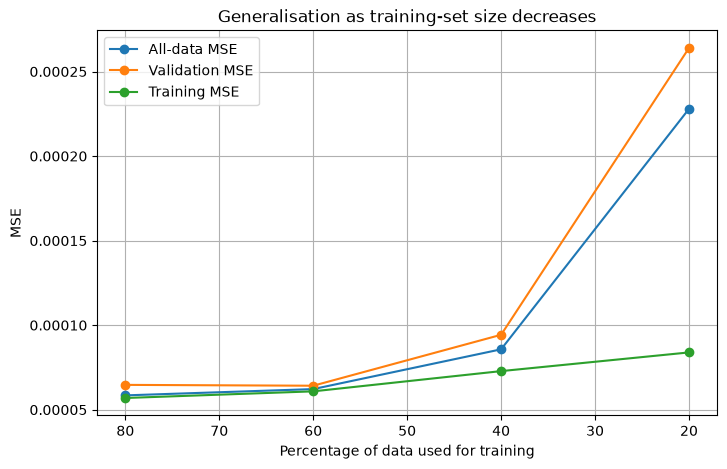

In [148]:
GENERALISATION_SEED = 123
rng = np.random.default_rng(GENERALISATION_SEED)
permuted_indices = rng.permutation(ndata)

training_fractions = [0.80, 0.60, 0.40, 0.20]
GENERALISATION_EPOCHS = 1000

generalisation_results = []


print_and_save_to_md_output("\n\nGENERALISATION STUDY RESULTS:\n")
print_and_save_to_md_output(
    f"{'Train %':>8} {'N train':>8} {'N val':>8} "
    f"{'Train MSE':>14} {'Val MSE':>14} {'All MSE':>14} "
    f"{'Conv.<0.01':>14}"
)
print_and_save_to_md_output("-" * 100)

for fraction in training_fractions:
    ntrain = int(fraction * ndata)
    train_idx = permuted_indices[:ntrain]
    val_idx = permuted_indices[ntrain:]

    X_train = patterns[:, train_idx]
    T_train = targets[:, train_idx]
    X_val = patterns[:, val_idx]
    T_val = targets[:, val_idx]

    mlp = MLP([2, BEST_HIDDEN, 1], seed=42)
    history = mlp.train(
        X_train, T_train,
        eta=BASE_ETA,
        alpha=BASE_ALPHA,
        epochs=GENERALISATION_EPOCHS,
        mode="batch"
    )

    train_out = mlp.forward(X_train)
    val_out = mlp.forward(X_val)
    all_out = mlp.forward(patterns)

    train_metrics = regression_metrics(train_out, T_train)
    val_metrics = regression_metrics(val_out, T_val)
    all_metrics = regression_metrics(all_out, targets)
    conv = convergence_epoch(history, threshold=0.01, key="train_mse")

    row = {
        "fraction": fraction,
        "ntrain": ntrain,
        "nval": ndata - ntrain,
        "train_metrics": train_metrics,
        "val_metrics": val_metrics,
        "all_metrics": all_metrics,
        "conv_epoch": conv,
        "model": mlp,
        "history": history,
        "all_output": all_out,
        "val_output": val_out,
        "train_indices": train_idx,
        "val_indices": val_idx,
    }
    generalisation_results.append(row)

    print_and_save_to_md_output(
        f"{fraction*100:>7.0f}% "
        f"{ntrain:>8} "
        f"{ndata-ntrain:>8} "
        f"{train_metrics['mse']:>14.8f} "
        f"{val_metrics['mse']:>14.8f} "
        f"{all_metrics['mse']:>14.8f} "
        f"{str(conv if conv is not None else '-'):>14}"
    )

plt.figure(figsize=(8, 5))
plt.plot(
    [r["fraction"] * 100 for r in generalisation_results],
    [r["all_metrics"]["mse"] for r in generalisation_results],
    marker="o",
    label="All-data MSE"
)
plt.plot(
    [r["fraction"] * 100 for r in generalisation_results],
    [r["val_metrics"]["mse"] for r in generalisation_results],
    marker="o",
    label="Validation MSE"
)
plt.plot(
    [r["fraction"] * 100 for r in generalisation_results],
    [r["train_metrics"]["mse"] for r in generalisation_results],
    marker="o",
    label="Training MSE"
)
plt.xlabel("Percentage of data used for training")
plt.ylabel("MSE")
plt.title("Generalisation as training-set size decreases")
plt.gca().invert_xaxis()
plt.legend()
plt.grid(True)
plt.show()

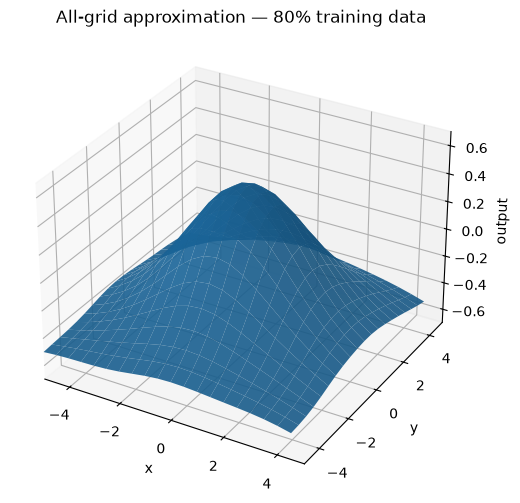

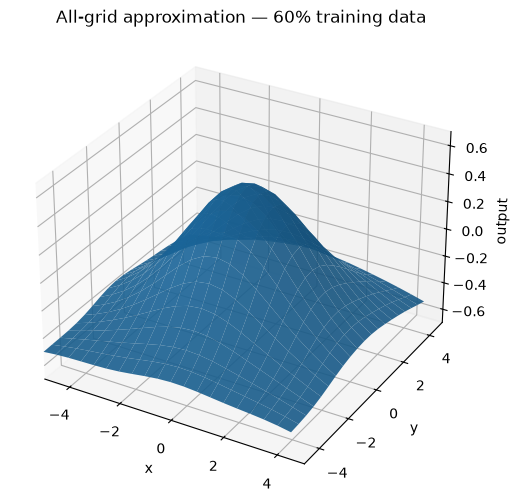

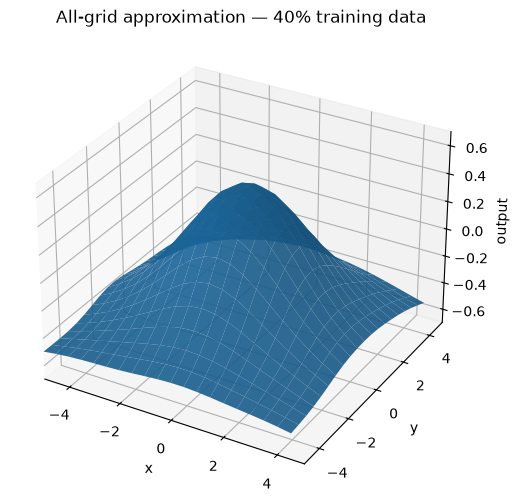

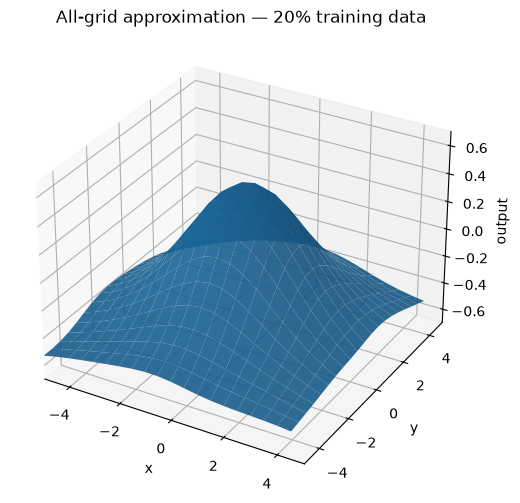

In [149]:
# 3D visualisation of the approximation for each training-set size.
for r in generalisation_results:
    plot_surface(
        xx, yy, r["all_output"].reshape(xx.shape),
        f"All-grid approximation — {r['fraction']*100:.0f}% training data"
    )

## 6. Convergence-speed experiment

The assignment asks whether convergence can be accelerated **without compromising generalisation**.

We therefore vary:
- learning rate `eta`;
- momentum parameter `alpha`.

The comparison records final all-data MSE and convergence epoch. The candidate setting should be judged by the trade-off between speed and approximation/generalisation error rather than by speed alone.



CONVERGENCE STUDY RESULTS:

     eta    alpha      Final MSE        Min MSE     Conv.<0.01     Stable
-------------------------------------------------------------------------------------
   0.010     0.00     0.04442744     0.04443721              -       True
   0.010     0.50     0.03599229     0.03600693              -       True
   0.010     0.90     0.00749353     0.00750758            852       True
   0.050     0.00     0.01997826     0.01999793              -       True
   0.050     0.50     0.00743343     0.00744723            846       True
   0.050     0.90     0.00041883     0.00041944            176       True
   0.100     0.00     0.00742601     0.00743978            846       True
   0.100     0.50     0.00200919     0.00201295            424       True
   0.100     0.90     0.00015344     0.00015368             91       True
   0.200     0.00     0.00200847     0.00201223            423       True
   0.200     0.50     0.00057810     0.00057901            212       T

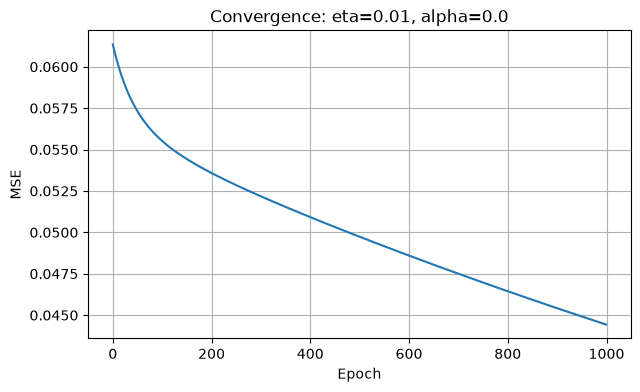

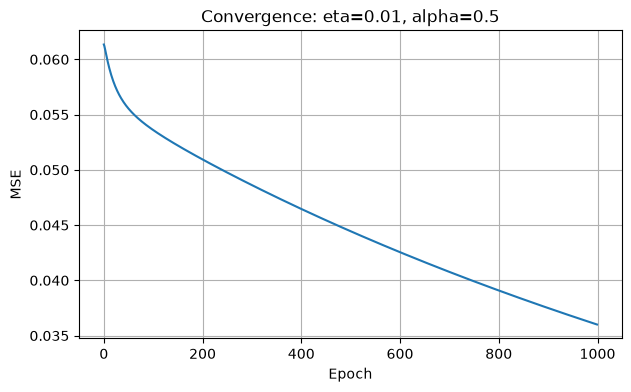

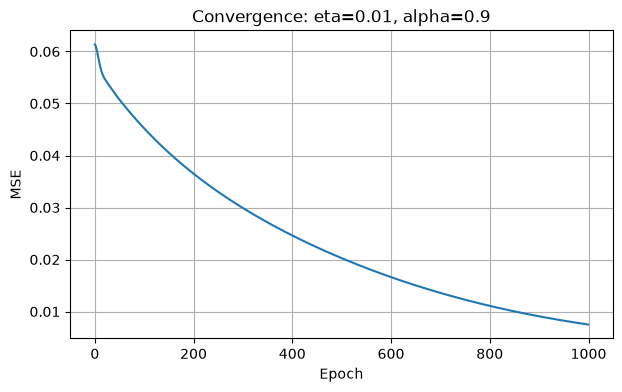

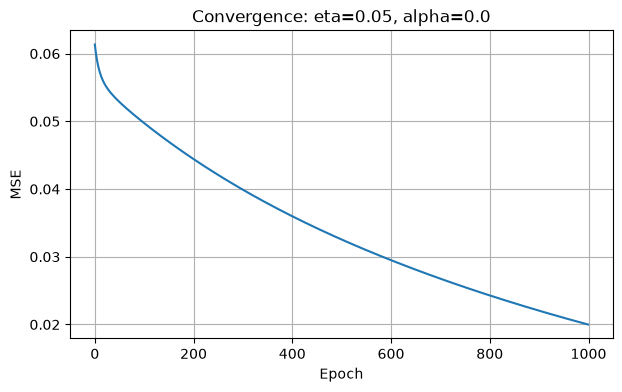

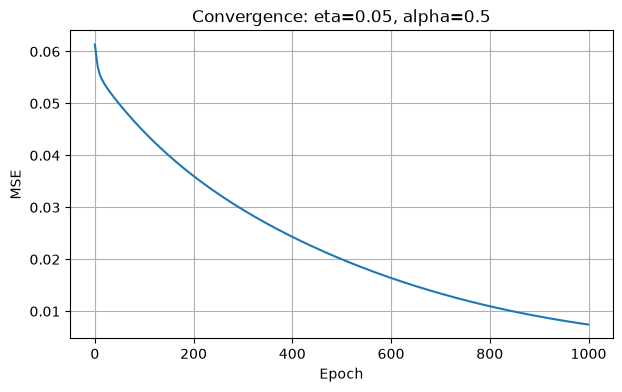

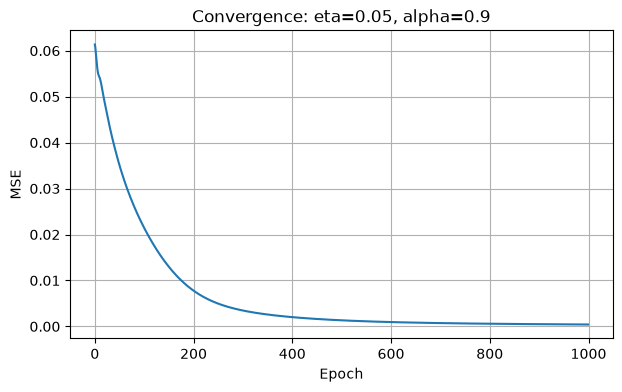

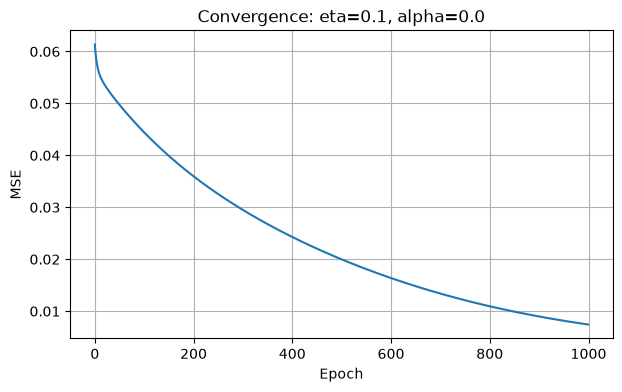

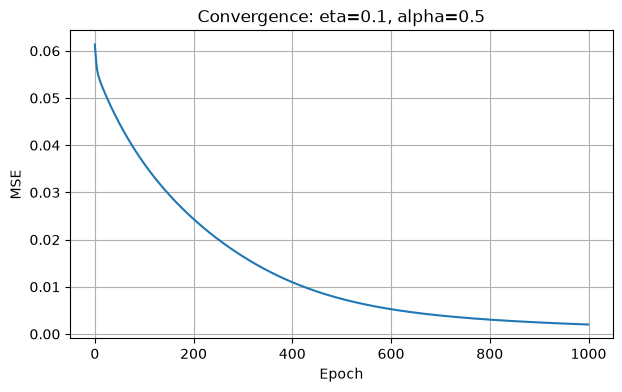

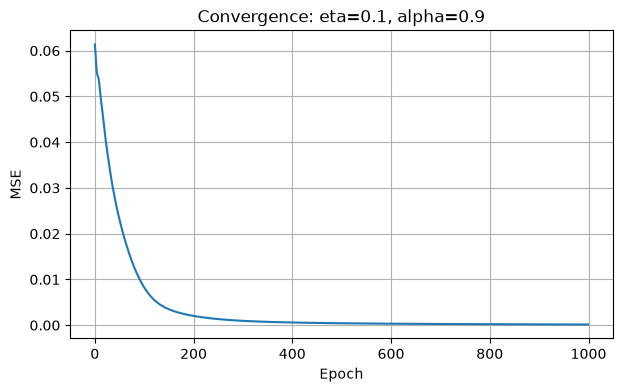

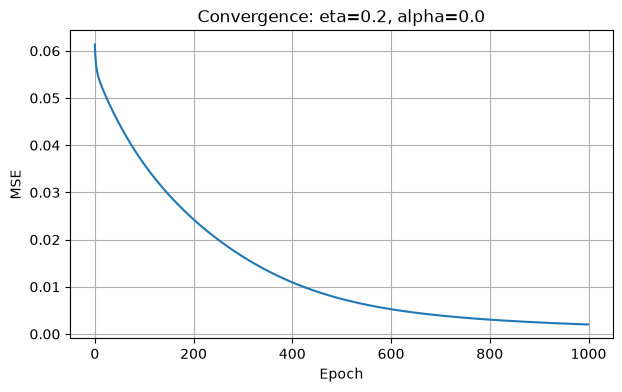

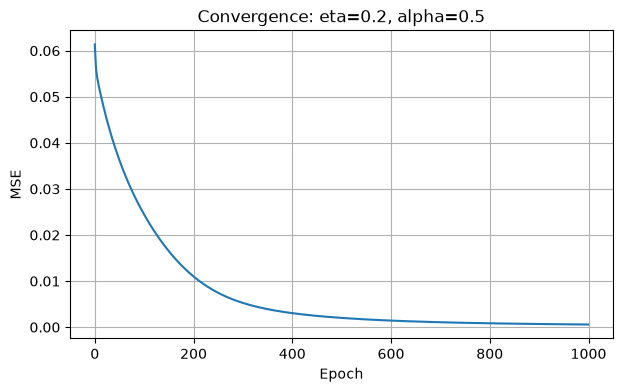

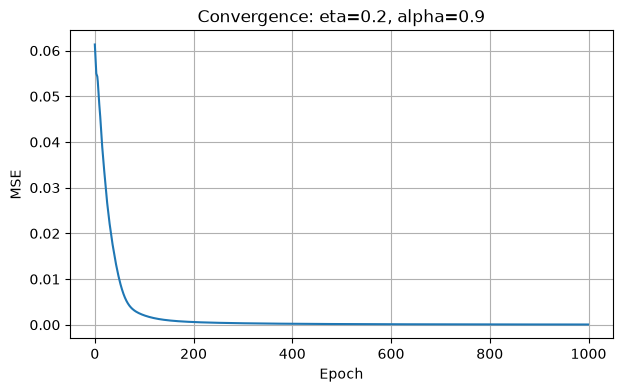

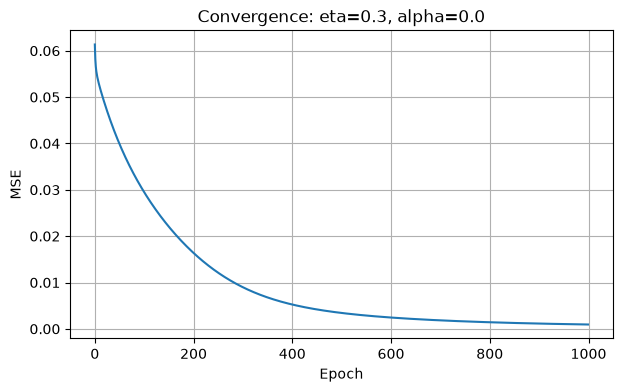

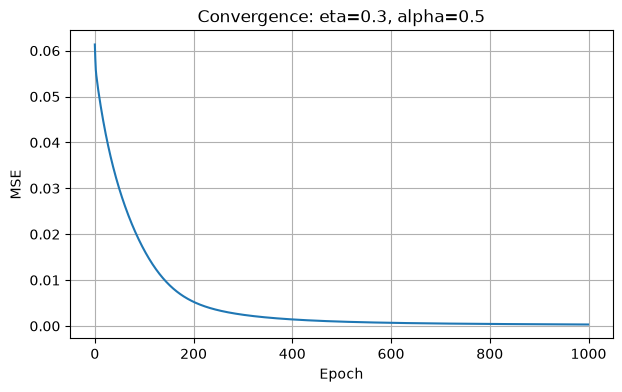

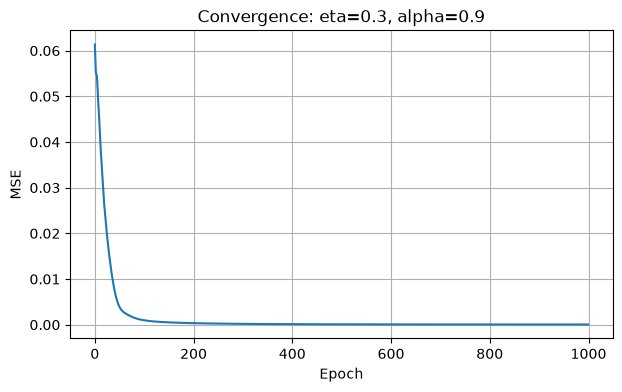

In [150]:
eta_values = [0.01, 0.05, 0.1, 0.2, 0.3]
alpha_values = [0.0, 0.5, 0.9]

CONVERGENCE_EPOCHS = 1000
convergence_results = []

print_and_save_to_md_output("\n\nCONVERGENCE STUDY RESULTS:\n")

print_and_save_to_md_output(
    f"{'eta':>8} {'alpha':>8} {'Final MSE':>14} "
    f"{'Min MSE':>14} {'Conv.<0.01':>14} {'Stable':>10}"
)
print_and_save_to_md_output("-" * 85)

for eta in eta_values:
    for alpha in alpha_values:
        mlp = MLP([2, BEST_HIDDEN, 1], seed=42)

        try:
            history = mlp.train(
                patterns, targets,
                eta=eta,
                alpha=alpha,
                epochs=CONVERGENCE_EPOCHS,
                mode="batch"
            )
            out = mlp.forward(patterns)
            metrics = regression_metrics(out, targets)
            history_array = np.asarray(history["train_mse"])

            finite = np.all(np.isfinite(history_array)) and np.all(np.isfinite(out))
            conv = convergence_epoch(history, threshold=0.01)

            result = {
                "eta": eta,
                "alpha": alpha,
                "final_mse": metrics["mse"],
                "min_mse": float(np.min(history_array)) if finite else np.inf,
                "conv_epoch": conv,
                "stable": finite,
                "history": history,
                "model": mlp,
                "output": out,
            }
        except Exception as e:
            result = {
                "eta": eta, "alpha": alpha,
                "final_mse": np.inf, "min_mse": np.inf,
                "conv_epoch": None, "stable": False,
                "history": None, "model": None, "output": None,
                "error": str(e)
            }

        convergence_results.append(result)

        print_and_save_to_md_output(
            f"{eta:>8.3f} {alpha:>8.2f} "
            f"{result['final_mse']:>14.8f} "
            f"{result['min_mse']:>14.8f} "
            f"{str(result['conv_epoch'] if result['conv_epoch'] is not None else '-'):>14} "
            f"{str(result['stable']):>10}"
        )

# Show the training curves for all tested settings.
for r in convergence_results:
    if r["history"] is not None and r["stable"]:
        plt.figure(figsize=(7, 4))
        plt.plot(r["history"]["train_mse"])
        plt.xlabel("Epoch")
        plt.ylabel("MSE")
        plt.title(f"Convergence: eta={r['eta']}, alpha={r['alpha']}")
        plt.grid(True)
        plt.show()


CONVERGENCE COMPARISON
----------------------
     eta    alpha    Conv. epoch      Final MSE
-------------------------------------------------------
   0.300     0.90             36     0.00004839
   0.200     0.90             50     0.00006171
   0.100     0.90             91     0.00015344
   0.300     0.50            142     0.00031921
   0.050     0.90            176     0.00041883
   0.200     0.50            212     0.00057810
   0.300     0.00            282     0.00093998
   0.200     0.00            423     0.00200847
   0.100     0.50            424     0.00200919
   0.050     0.50            846     0.00743343
   0.100     0.00            846     0.00742601
   0.010     0.90            852     0.00749353

Fastest configuration reaching MSE < 0.01:
eta=0.3, alpha=0.9
Convergence epoch=36
Final all-data MSE=0.00004839
Baseline all-data MSE=0.00010904
Baseline convergence epoch=77


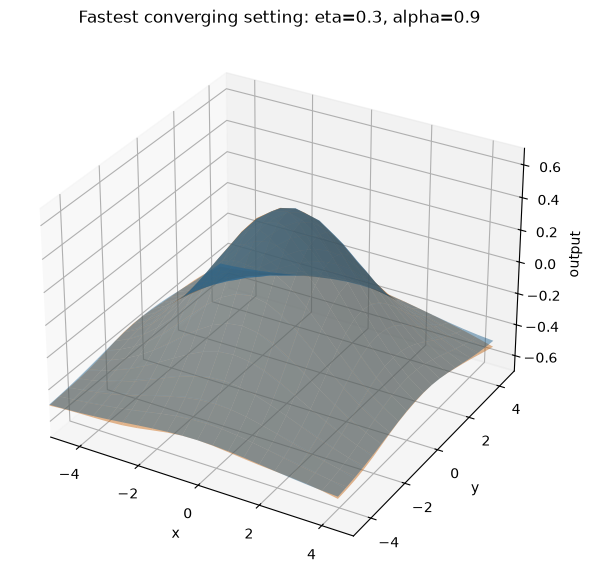

In [151]:
# Rank settings by convergence speed among runs that reached MSE < 0.01.
successful_convergence = [
    r for r in convergence_results
    if r["stable"] and r["conv_epoch"] is not None
]

print_and_save_to_md_output("\nCONVERGENCE COMPARISON")
print_and_save_to_md_output("----------------------")

if successful_convergence:
    successful_convergence = sorted(successful_convergence, key=lambda r: r["conv_epoch"])
    print_and_save_to_md_output(f"{'eta':>8} {'alpha':>8} {'Conv. epoch':>14} {'Final MSE':>14}")
    print_and_save_to_md_output("-" * 55)
    for r in successful_convergence:
        print_and_save_to_md_output(
            f"{r['eta']:>8.3f} {r['alpha']:>8.2f} "
            f"{r['conv_epoch']:>14} {r['final_mse']:>14.8f}"
        )
else:
    print_and_save_to_md_output("No tested configuration reached MSE < 0.01.")

# Compare the fastest converging configuration against the baseline
# using the all-data approximation.
if successful_convergence:
    fastest = successful_convergence[0]
    print_and_save_to_md_output("\nFastest configuration reaching MSE < 0.01:")
    print_and_save_to_md_output(f"eta={fastest['eta']}, alpha={fastest['alpha']}")
    print_and_save_to_md_output(f"Convergence epoch={fastest['conv_epoch']}")
    print_and_save_to_md_output(f"Final all-data MSE={fastest['final_mse']:.8f}")
    print_and_save_to_md_output(f"Baseline all-data MSE={baseline_metrics['mse']:.8f}")
    print_and_save_to_md_output(f"Baseline convergence epoch={convergence_epoch(baseline_history)}")

    plot_target_vs_output(
        xx, yy, z, fastest["output"],
        f"Fastest converging setting: eta={fastest['eta']}, alpha={fastest['alpha']}"
    )

## 7. Repeated runs / stochasticity check

The lab notes that simulations are stochastic due to random initialisation. This section repeats the candidate model with several seeds and reports the first and second statistical moments (mean and standard deviation) of the final all-data MSE.

This is useful evidence for the report and helps avoid drawing conclusions from one lucky/unlucky initialisation.

In [152]:
STOCHASTIC_SEEDS = [0, 1, 2, 3, 4]
stochastic_mses = []
stochastic_conv = []

for seed in STOCHASTIC_SEEDS:
    mlp = MLP([2, BEST_HIDDEN, 1], seed=seed)
    history = mlp.train(
        patterns, targets,
        eta=BASE_ETA,
        alpha=BASE_ALPHA,
        epochs=BASE_EPOCHS,
        mode="batch"
    )
    out = mlp.forward(patterns)
    metrics = regression_metrics(out, targets)
    stochastic_mses.append(metrics["mse"])
    conv = convergence_epoch(history)
    if conv is not None:
        stochastic_conv.append(conv)

print_and_save_to_md_output("\n\nREPEATED RANDOM INITIALISATIONS")
print_and_save_to_md_output("-------------------------------")
for seed, mse in zip(STOCHASTIC_SEEDS, stochastic_mses):
    print_and_save_to_md_output(f"seed={seed}: final all-data MSE={mse:.8f}")

print_and_save_to_md_output(f"Mean final MSE: {np.mean(stochastic_mses):.8f}")
print_and_save_to_md_output(f"Std final MSE:  {np.std(stochastic_mses):.8f}")
print_and_save_to_md_output(f"Variance final MSE: {np.var(stochastic_mses):.8f}")
print_and_save_to_md_output(
    "Convergence epoch mean/std: "
    f"{np.mean(stochastic_conv):.2f} / {np.std(stochastic_conv):.2f}"
    if stochastic_conv else
    "No run reached MSE < 0.01."
)



REPEATED RANDOM INITIALISATIONS
-------------------------------
seed=0: final all-data MSE=0.00019381
seed=1: final all-data MSE=0.00018081
seed=2: final all-data MSE=0.00008654
seed=3: final all-data MSE=0.00008861
seed=4: final all-data MSE=0.00011093
Mean final MSE: 0.00013214
Std final MSE:  0.00004603
Variance final MSE: 0.00000000
Convergence epoch mean/std: 70.60 / 16.73


## 8. Optional experiment: Gaussian noise

This is explicitly marked non-mandatory in the assignment. Noise is added to the **training targets only**, while the original noiseless function remains the reference for evaluating generalisation.

The variance is controlled through `sigma²`, with zero-mean Gaussian noise `N(0, sigma²)`.



NOISE STUDY RESULTS:

    Variance    Train noisy MSE      All clean MSE   Validation clean MSE
---------------------------------------------------------------------------
      0.0001         0.00013596         0.00006119             0.00006297
      0.0010         0.00087429         0.00010144             0.00008816
      0.0100         0.00835941         0.00052949             0.00042562
      0.0500         0.04150215         0.00282957             0.00244303
      0.1000         0.08302513         0.00536664             0.00466047


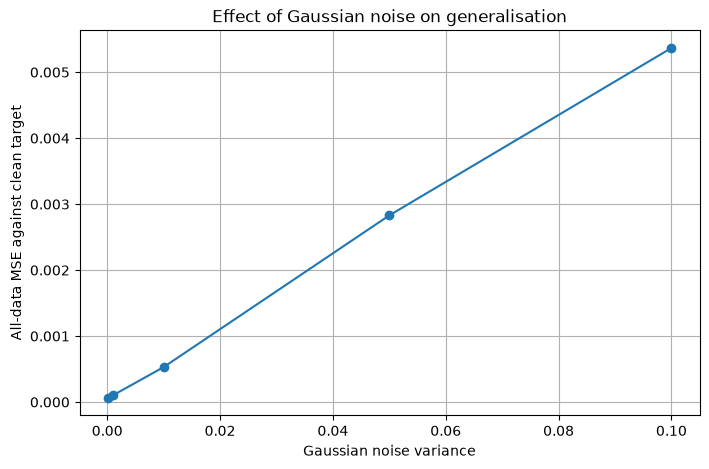

In [153]:
NOISE_SEED = 999
noise_variances = [0.0001, 0.001, 0.01, 0.05, 0.10]
NOISE_EPOCHS = 1000

# Use the 80% training subset from the same permutation as above.
noise_fraction = 0.80
noise_ntrain = int(noise_fraction * ndata)
noise_train_idx = permuted_indices[:noise_ntrain]
noise_val_idx = permuted_indices[noise_ntrain:]

X_noise_train = patterns[:, noise_train_idx]
T_noise_clean = targets[:, noise_train_idx]

noise_results = []


print_and_save_to_md_output("\n\nNOISE STUDY RESULTS:\n")
print_and_save_to_md_output(
    f"{'Variance':>12} {'Train noisy MSE':>18} "
    f"{'All clean MSE':>18} {'Validation clean MSE':>22}"
)
print_and_save_to_md_output("-" * 75)

for variance in noise_variances:
    rng_noise = np.random.default_rng(NOISE_SEED)
    noise = rng_noise.normal(0, np.sqrt(variance), size=T_noise_clean.shape)
    T_noise = T_noise_clean + noise

    mlp = MLP([2, BEST_HIDDEN, 1], seed=42)
    history = mlp.train(
        X_noise_train, T_noise,
        eta=BASE_ETA,
        alpha=BASE_ALPHA,
        epochs=NOISE_EPOCHS,
        mode="batch"
    )

    noisy_train_out = mlp.forward(X_noise_train)
    all_clean_out = mlp.forward(patterns)
    val_clean_out = mlp.forward(patterns[:, noise_val_idx])

    noisy_train_metrics = regression_metrics(noisy_train_out, T_noise)
    all_clean_metrics = regression_metrics(all_clean_out, targets)
    val_clean_metrics = regression_metrics(
        val_clean_out, targets[:, noise_val_idx]
    )

    noise_results.append({
        "variance": variance,
        "history": history,
        "model": mlp,
        "train_noisy_metrics": noisy_train_metrics,
        "all_clean_metrics": all_clean_metrics,
        "val_clean_metrics": val_clean_metrics,
        "output": all_clean_out,
    })

    print_and_save_to_md_output(
        f"{variance:>12.4f} "
        f"{noisy_train_metrics['mse']:>18.8f} "
        f"{all_clean_metrics['mse']:>18.8f} "
        f"{val_clean_metrics['mse']:>22.8f}"
    )

plt.figure(figsize=(8, 5))
plt.plot(
    [r["variance"] for r in noise_results],
    [r["all_clean_metrics"]["mse"] for r in noise_results],
    marker="o"
)
plt.xlabel("Gaussian noise variance")
plt.ylabel("All-data MSE against clean target")
plt.title("Effect of Gaussian noise on generalisation")
plt.grid(True)
plt.show()

## 9. Final report-ready summary

This cell prints a compact summary that can be pasted directly into the report-writing chat together with the plots above.

In [154]:
print_and_save_to_md_output("=" * 90)
print_and_save_to_md_output("SECTION 3.1.3 — REPORT-READY SUMMARY")
print_and_save_to_md_output("=" * 90)

print_and_save_to_md_output("\nDATASET")
print_and_save_to_md_output(f"Grid: {gridsize}x{gridsize} = {ndata} samples")
print_and_save_to_md_output("Function: f(x,y) = exp(-(x^2+y^2)/10) - 0.5")

print_and_save_to_md_output("\nBASELINE")
print_and_save_to_md_output(f"Architecture: 2-{BASE_HIDDEN}-1")
print_and_save_to_md_output(f"eta={BASE_ETA}, alpha={BASE_ALPHA}, epochs={BASE_EPOCHS}")
print_metrics("All-data", baseline_metrics)
print_and_save_to_md_output(f"Convergence epoch (<0.01): {convergence_epoch(baseline_history) or 'not reached'}")

print_and_save_to_md_output("\nHIDDEN-LAYER STUDY")
for r in hidden_results:
    print_and_save_to_md_output(
        f"hidden={r['hidden']:2d} | "
        f"final MSE={r['final_mse']:.8f} | "
        f"min MSE={r['min_mse']:.8f} | "
        f"conv={r['conv_epoch'] if not np.isnan(r['conv_epoch']) else '-'}"
    )

print_and_save_to_md_output(f"\nSELECTED CANDIDATE: 2-{BEST_HIDDEN}-1")

print_and_save_to_md_output("\nGENERALISATION")
for r in generalisation_results:
    print_and_save_to_md_output(
        f"{r['fraction']*100:>3.0f}% train ({r['ntrain']:3d} samples) | "
        f"train MSE={r['train_metrics']['mse']:.8f} | "
        f"val MSE={r['val_metrics']['mse']:.8f} | "
        f"all-data MSE={r['all_metrics']['mse']:.8f} | "
        f"conv={r['conv_epoch'] if r['conv_epoch'] is not None else '-'}"
    )

print_and_save_to_md_output("\nCONVERGENCE / HYPERPARAMETERS")
for r in convergence_results:
    print_and_save_to_md_output(
        f"eta={r['eta']:.3f}, alpha={r['alpha']:.2f} | "
        f"final MSE={r['final_mse']:.8f} | "
        f"conv={r['conv_epoch'] if r['conv_epoch'] is not None else '-'} | "
        f"stable={r['stable']}"
    )

print_and_save_to_md_output("\nSTOCHASTICITY")
print_and_save_to_md_output(f"Seeds: {STOCHASTIC_SEEDS}")
print_and_save_to_md_output(f"Mean MSE: {np.mean(stochastic_mses):.8f}")
print_and_save_to_md_output(f"Std MSE:  {np.std(stochastic_mses):.8f}")
print_and_save_to_md_output(f"Variance:  {np.var(stochastic_mses):.8f}")

print_and_save_to_md_output("\nOPTIONAL NOISE")
for r in noise_results:
    print_and_save_to_md_output(
        f"variance={r['variance']:.4f} | "
        f"noisy train MSE={r['train_noisy_metrics']['mse']:.8f} | "
        f"all clean MSE={r['all_clean_metrics']['mse']:.8f} | "
        f"val clean MSE={r['val_clean_metrics']['mse']:.8f}"
    )

print_and_save_to_md_output("=" * 90)
print_and_save_to_md_output("END OF EXPERIMENTS")
print_and_save_to_md_output("=" * 90)

SECTION 3.1.3 — REPORT-READY SUMMARY

DATASET
Grid: 20x20 = 400 samples
Function: f(x,y) = exp(-(x^2+y^2)/10) - 0.5

BASELINE
Architecture: 2-20-1
eta=0.2, alpha=0.9, epochs=1000
All-data: MSE=0.00010904, RMSE=0.01044238, MAE=0.00850347, MaxAbsError=0.03368805
Convergence epoch (<0.01): 77

HIDDEN-LAYER STUDY
hidden= 1 | final MSE=0.06252871 | min MSE=0.06253445 | conv=-
hidden= 2 | final MSE=0.03791869 | min MSE=0.03791870 | conv=-
hidden= 3 | final MSE=0.00213734 | min MSE=0.00213765 | conv=331
hidden= 4 | final MSE=0.00180165 | min MSE=0.00180194 | conv=174
hidden= 5 | final MSE=0.00030806 | min MSE=0.00030822 | conv=192
hidden= 7 | final MSE=0.00026887 | min MSE=0.00026904 | conv=123
hidden=10 | final MSE=0.00018714 | min MSE=0.00018733 | conv=108
hidden=15 | final MSE=0.00028396 | min MSE=0.00028412 | conv=91
hidden=20 | final MSE=0.00010904 | min MSE=0.00010920 | conv=77
hidden=25 | final MSE=0.00006171 | min MSE=0.00006177 | conv=50

SELECTED CANDIDATE: 2-25-1

GENERALISATION
 8